# Introduction to Classification

In [1]:
import pandas as pd
import numpy as np

## Classifying Tropical Storms

The "storms" data set contains data on tropical storms since 1975. Suppose we want to use this data to train a classification model that predicts whether or not a storm is a hurricane based on its wind speed and pressure.


In [2]:
df_storms = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/main/data/storms.csv")
df_storms["hurricane"] = (df_storms["status"] == "hurricane")
df_storms


,name,year,month,day,hour,lat,long,status,category,wind,pressure,tropicalstorm_force_diameter,hurricane_force_diameter,hurricane
0,Amy,1975,6,27,0,27.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
1,Amy,1975,6,27,6,28.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
2,Amy,1975,6,27,12,29.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
3,Amy,1975,6,27,18,30.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
4,Amy,1975,6,28,0,31.5,-78.8,tropical depression,NaN,25,1012,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19061,Wanda,2021,11,7,0,37.4,-37.4,tropical storm,NaN,35,1003,60.0,0.0,False
19062,Wanda,2021,11,7,6,38.1,-36.4,tropical storm,NaN,35,1004,60.0,0.0,False
19063,Wanda,2021,11,7,12,39.2,-34.9,other low,NaN,35,1006,90.0,0.0,False
19064,Wanda,2021,11,7,18,40.9,-32.8,other low,NaN,40,1006,90.0,0.0,False


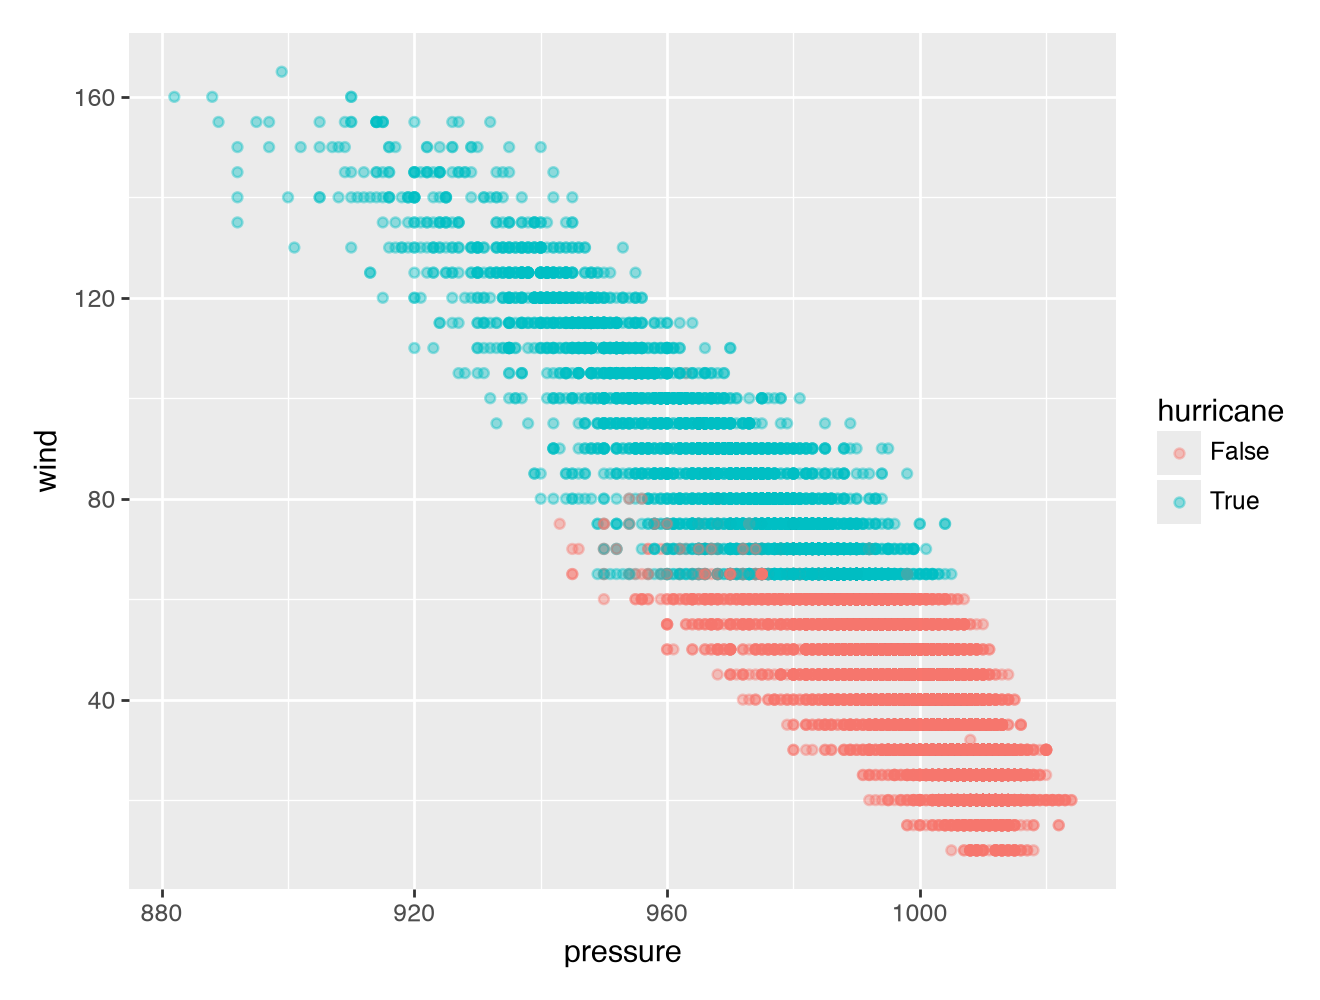

In [3]:
from plotnine import *

(
    ggplot(
        df_storms,
        aes(x="pressure", y="wind", color="hurricane")
    )
    + geom_point(alpha=0.4)
)

1. Inspect the scatterplot above. Suggest a simple classification rule that you suspect will have both high precision and high recall for the hurriance class based on the training data. **Without doing any coding, specify your rule and explain your reasoning.** This is NOT asking you to do nearest neighbors. Rather suggest a simple classification rule based on what you see in the plot.

**DISCUSS WITH YOUR PARTNER.**

2. For each of the following **compute the value and write a clearly worded sentence interpreting the value as a percentage in context.** Again, this is NOT asking you to fit a nearest neighbors model. You can write code, but you should only need to write basic code to make your predictions and get relevant counts from the training data. You can compute things like fractions by hand.

  a. training accuracy  
  b. training precision for the hurricane class  
  c. training recall for the hurricane class  
  d. training F1 score for the hurricane class  
  e. training precision for the non-hurricane class    
  f. training recall for the non-hurricane class  
  g. training F1 score for the non-hurricane class  

In [4]:
# ENTER YOUR CODE HERE
# Apply the classification rule from Question 1
df_storms["predicted_hurricane"] = df_storms["wind"] >= 65

# Shorter names for the actual and predicted classes
actual = df_storms["hurricane"]
predicted = df_storms["predicted_hurricane"]

# Calculate the four confusion-matrix counts
TP = (actual & predicted).sum()
FP = (~actual & predicted).sum()
FN = (actual & ~predicted).sum()
TN = (~actual & ~predicted).sum()

print(f"TP = {TP}")
print(f"FP = {FP}")
print(f"FN = {FN}")
print(f"TN = {TN}")

# a. Overall accuracy
accuracy = (TP + TN) / (TP + FP + FN + TN)

# b-d. Scores when hurricane is the class of interest
hurricane_precision = TP / (TP + FP)
hurricane_recall = TP / (TP + FN)
hurricane_f1 = (
    2 * hurricane_precision * hurricane_recall
    / (hurricane_precision + hurricane_recall)
)

# e-g. Scores when non-hurricane is the class of interest
non_hurricane_precision = TN / (TN + FN)
non_hurricane_recall = TN / (TN + FP)
non_hurricane_f1 = (
    2 * non_hurricane_precision * non_hurricane_recall
    / (non_hurricane_precision + non_hurricane_recall)
)

print(f"\nAccuracy: {accuracy:.2%}")
print(f"Hurricane precision: {hurricane_precision:.2%}")
print(f"Hurricane recall: {hurricane_recall:.2%}")
print(f"Hurricane F1 score: {hurricane_f1:.2%}")
print(f"Non-hurricane precision: {non_hurricane_precision:.2%}")
print(f"Non-hurricane recall: {non_hurricane_recall:.2%}")
print(f"Non-hurricane F1 score: {non_hurricane_f1:.2%}")

TP = 4684
FP = 128
FN = 0
TN = 14254

Accuracy: 99.33%
Hurricane precision: 97.34%
Hurricane recall: 100.00%
Hurricane F1 score: 98.65%
Non-hurricane precision: 100.00%
Non-hurricane recall: 99.11%
Non-hurricane F1 score: 99.55%


**DISCUSS WITH YOUR PARTNER.**

3. The "status" variable contains further breakdown of the non-hurricane class. Suppose we fit a **10-nearest neighbors** classification model for predicting status from wind speed and pressure. Without doing any coding, what status would the model predict for a storm with a pressure of 975 and wind speed of 39? **Explain your reasoning without doing any coding**. Hint: look at the scatterplot below, but be careful since some points are superimposed.

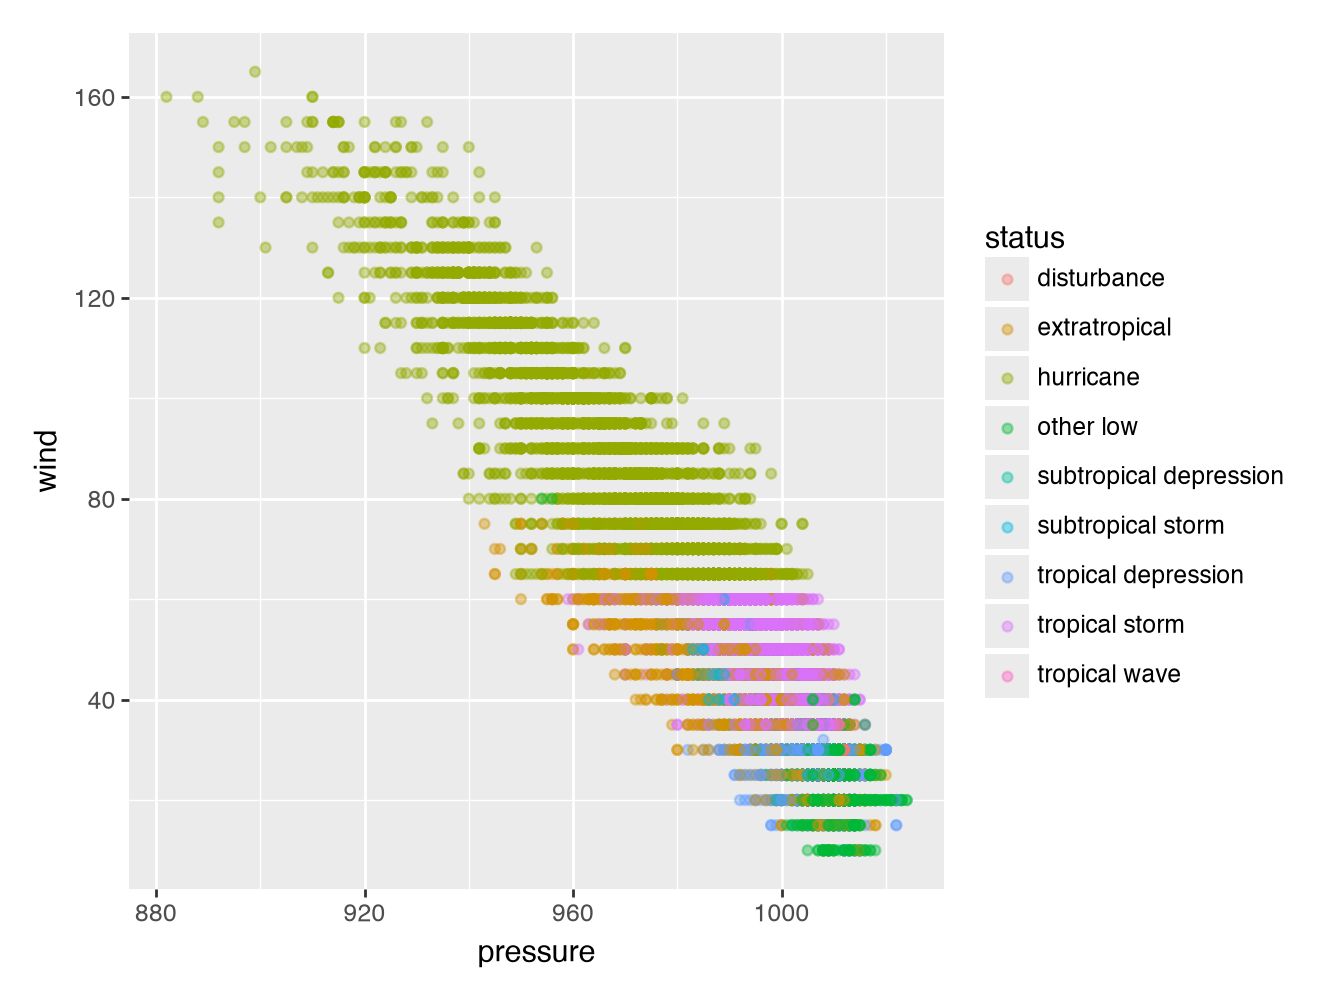

In [5]:
(
    ggplot(
        df_storms,
        aes(x="pressure", y="wind", color="status")
    )
    + geom_point(alpha=0.4)
)

**DISCUSS WITH YOUR PARTNER.**

4. Suppose we fit a **10-nearest neighbors** classification model for predicting status from wind speed and pressure. Without doing any coding, which classes do you think would have the lowest recall based on the training data? **Explain your reasoning without doing any coding.** Hint: look at the scatterplot above, but be careful since some points are superimposed.

**DISCUSS WITH YOUR PARTNER.**

## Practice Activity Titanic Data

We'll use $k$-nearest neighbors to predict who survives based on age, sex, and class.

In [6]:
df_titanic = pd.read_csv("https://dlsun.github.io/pods/data/titanic.csv ")

# drop the NaN for age since we're using it as a predictor
df_titanic = df_titanic.dropna(subset = ["age"])

df_titanic

,name,gender,age,class,embarked,country,ticketno,fare,survived
0,"Abbing, Mr. Anthony",male,42.0,3rd,S,United States,5547.0,7.11,0
1,"Abbott, Mr. Eugene Joseph",male,13.0,3rd,S,United States,2673.0,20.05,0
2,"Abbott, Mr. Rossmore Edward",male,16.0,3rd,S,United States,2673.0,20.05,0
3,"Abbott, Mrs. Rhoda Mary 'Rosa'",female,39.0,3rd,S,England,2673.0,20.05,1
4,"Abelseth, Miss. Karen Marie",female,16.0,3rd,S,Norway,348125.0,7.13,1
...,...,...,...,...,...,...,...,...,...
2202,"Wynn, Mr. Walter",male,41.0,deck crew,B,England,NaN,NaN,1
2203,"Yearsley, Mr. Harry",male,40.0,victualling crew,S,England,NaN,NaN,1
2204,"Young, Mr. Francis James",male,32.0,engineering crew,S,England,NaN,NaN,0
2205,"Zanetti, Sig. Minio",male,20.0,restaurant staff,S,England,NaN,NaN,0


1\. Train a 10-nearest neighbors model to predict whether or not a passenger on the Titanic survived, using their age, sex, and class as features.

In [7]:
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, precision_recall_curve, roc_curve, roc_auc_score,
                             average_precision_score, log_loss)

In [10]:
# YOUR CODE HERE. ADD CELLS AS NEEDED
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier

# Features and target
features = ["age", "gender", "class"]
X = df_titanic[features]
y = df_titanic["survived"]

# Scale age and convert gender/class into numeric indicator columns
preprocessing = ColumnTransformer([
    ("age", StandardScaler(), ["age"]),
    ("categories",
     OneHotEncoder(handle_unknown="ignore", sparse_output=False),
     ["gender", "class"])
])

# Build and train the 10-nearest-neighbors model
titanic_model = make_pipeline(
    preprocessing,
    KNeighborsClassifier(n_neighbors=10)
)

titanic_model.fit(X, y)

# Save training predictions and survival probabilities for later questions
titanic_pred = titanic_model.predict(X)
titanic_prob = titanic_model.predict_proba(X)[:, 1]

2\. Use your model to predict whether a 20-year old female in first-class would survive. What about a 20-year old female in third-class? What are the predicted probabilities for each?

In [12]:
# YOUR CODE HERE. ADD CELLS AS NEEDED
# Create the two passengers we want predictions for
new_passengers = pd.DataFrame({
    "age": [20, 20],
    "gender": ["female", "female"],
    "class": ["1st", "3rd"]
})

# Predict survival and the probability of survival
new_passengers["predicted_survival"] = titanic_model.predict(new_passengers)
new_passengers["probability_of_survival"] = (
    titanic_model.predict_proba(new_passengers)[:, 1]
)

# Make the prediction easier to read
new_passengers["prediction"] = new_passengers[
    "predicted_survival"
].map({
    1: "Survive",
    0: "Not survive"
})

new_passengers

,age,gender,class,predicted_survival,probability_of_survival,prediction
0,20,female,1st,1,1.0,Survive
1,20,female,3rd,0,0.2,Not survive


3\. Calculate and interpret the training precision, recall, and F1 score for predicting survivors.

In [13]:
# YOUR CODE HERE. ADD CELLS AS NEEDED
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Confusion matrix for the training predictions
cm = confusion_matrix(y, titanic_pred, labels=[0, 1])
TN, FP, FN, TP = cm.ravel()

# Calculate scores with survivor (1) as the positive class
survivor_precision = precision_score(y, titanic_pred, pos_label=1)
survivor_recall = recall_score(y, titanic_pred, pos_label=1)
survivor_f1 = f1_score(y, titanic_pred, pos_label=1)

print(f"TP = {TP}, FP = {FP}, FN = {FN}, TN = {TN}")
print(f"Survivor precision: {survivor_precision:.2%}")
print(f"Survivor recall: {survivor_recall:.2%}")
print(f"Survivor F1 score: {survivor_f1:.2%}")

TP = 379, FP = 67, FN = 332, TN = 1427
Survivor precision: 84.98%
Survivor recall: 53.31%
Survivor F1 score: 65.51%


4\. Calculate and interpret the training precision, recall, and F1 score for predicting non-survivors.

In [14]:
# YOUR CODE HERE. ADD CELLS AS NEEDED
# Calculate scores with non-survivor (0) as the class of interest
non_survivor_precision = precision_score(
    y, titanic_pred, pos_label=0
)

non_survivor_recall = recall_score(
    y, titanic_pred, pos_label=0
)

non_survivor_f1 = f1_score(
    y, titanic_pred, pos_label=0
)

print(f"Non-survivor precision: {non_survivor_precision:.2%}")
print(f"Non-survivor recall: {non_survivor_recall:.2%}")
print(f"Non-survivor F1 score: {non_survivor_f1:.2%}")

Non-survivor precision: 81.13%
Non-survivor recall: 95.52%
Non-survivor F1 score: 87.73%


5\. Since there are only two classes (survived or not) the model predicts survival if the predicted probability of survival is $0.5$ or higher. Change the threshold from 0.5 to 0.8 and compute the precision and recall for survivors and the non-survivors. How do the values compare to those with the threshold of 0.5?

In [15]:
# YOUR CODE HERE. ADD CELLS AS NEEDED
threshold_results = []

for threshold in [0.5, 0.8]:
    # Predict survival when probability is at least the threshold
    pred_threshold = (titanic_prob >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "survivor precision": precision_score(
            y, pred_threshold, pos_label=1
        ),
        "survivor recall": recall_score(
            y, pred_threshold, pos_label=1
        ),
        "non-survivor precision": precision_score(
            y, pred_threshold, pos_label=0
        ),
        "non-survivor recall": recall_score(
            y, pred_threshold, pos_label=0
        )
    })

# Display the results as percentages
threshold_results = pd.DataFrame(
    threshold_results
).set_index("threshold")

(threshold_results * 100).round(2)

,survivor precision,survivor recall,non-survivor precision,non-survivor recall
threshold,,,,
0.5,78.05,62.03,83.54,91.70
0.8,91.90,41.49,77.92,98.26


Increasing the survival threshold from 0.5 to 0.8 increases survivor precision but decreases survivor recall. The model makes fewer survival predictions, but those predictions are more reliable. For non-survivors, precision decreases while recall increases. Therefore, the higher threshold is better at avoiding false survival predictions, but it misses more passengers who actually survived.

6\. Plot the precision-recall curve for the survivors. Interpret what you see.

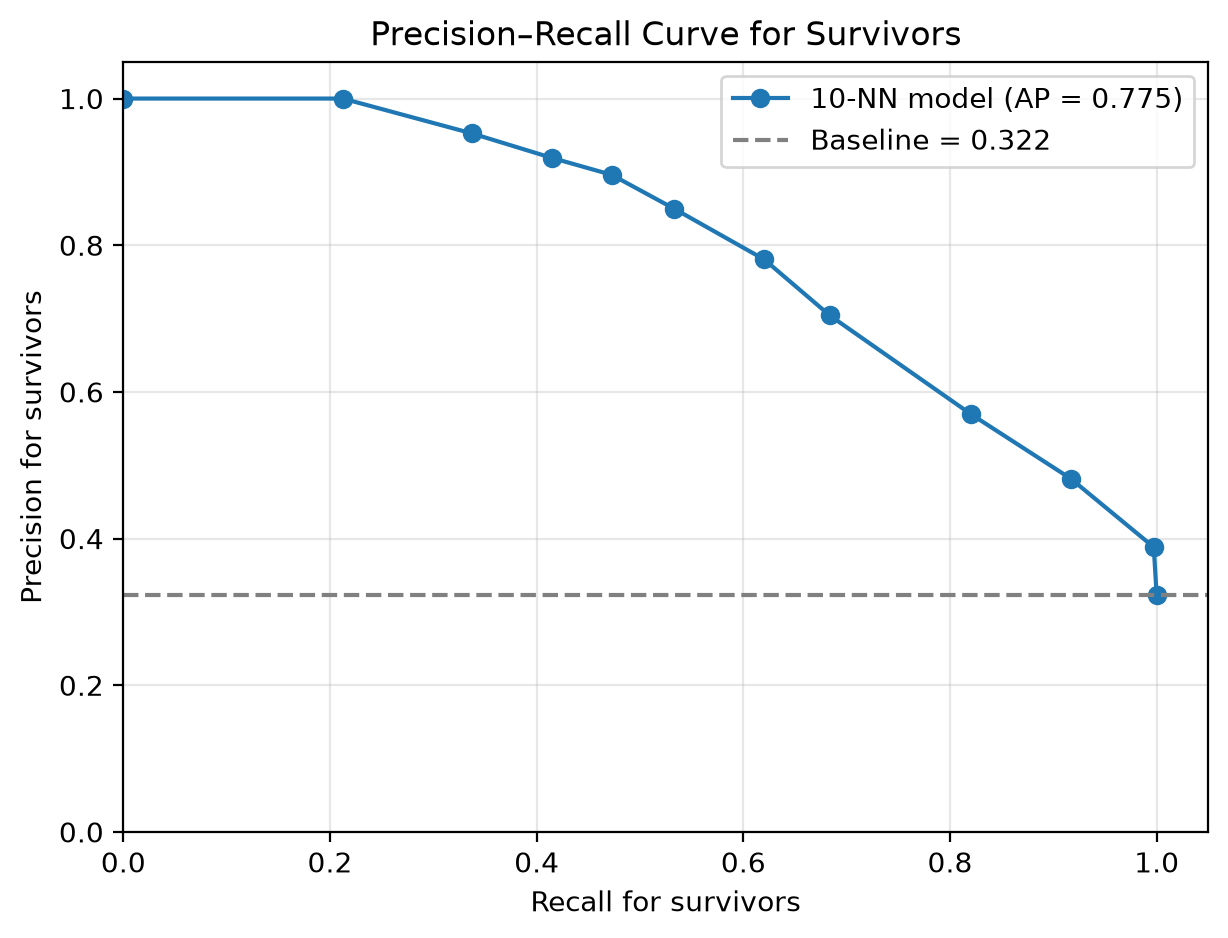

In [16]:
# YOUR CODE HERE. ADD CELLS AS NEEDED
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

# Calculate precision and recall across all survival thresholds
survivor_precision_curve, survivor_recall_curve, survivor_thresholds = (
    precision_recall_curve(
        y,
        titanic_prob,
        pos_label=1
    )
)

# Summarize the curve with average precision
survivor_ap = average_precision_score(y, titanic_prob)

# Plot recall on the x-axis and precision on the y-axis
plt.figure(figsize=(7, 5))

plt.plot(
    survivor_recall_curve,
    survivor_precision_curve,
    marker="o",
    label=f"10-NN model (AP = {survivor_ap:.3f})"
)

# Baseline precision equals the percentage of passengers who survived
plt.axhline(
    y.mean(),
    color="gray",
    linestyle="--",
    label=f"Baseline = {y.mean():.3f}"
)

plt.xlabel("Recall for survivors")
plt.ylabel("Precision for survivors")
plt.title("Precision–Recall Curve for Survivors")
plt.xlim(0, 1.05)
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

The precision–recall curve shows a trade-off between correctly identifying more survivors and making reliable survival predictions. Lower thresholds produce higher recall because the model predicts more passengers as survivors, but precision decreases because more non-survivors are incorrectly classified as survivors. Higher thresholds improve precision but reduce recall because the model becomes more selective and misses more actual survivors. The curve is generally above the baseline precision of 32.24%, indicating that the model provides useful information for predicting survivors. However, there is no threshold at which both precision and recall are perfect.

7\. Plot the precision-recall curve for non-survivors. Interpret what you see.

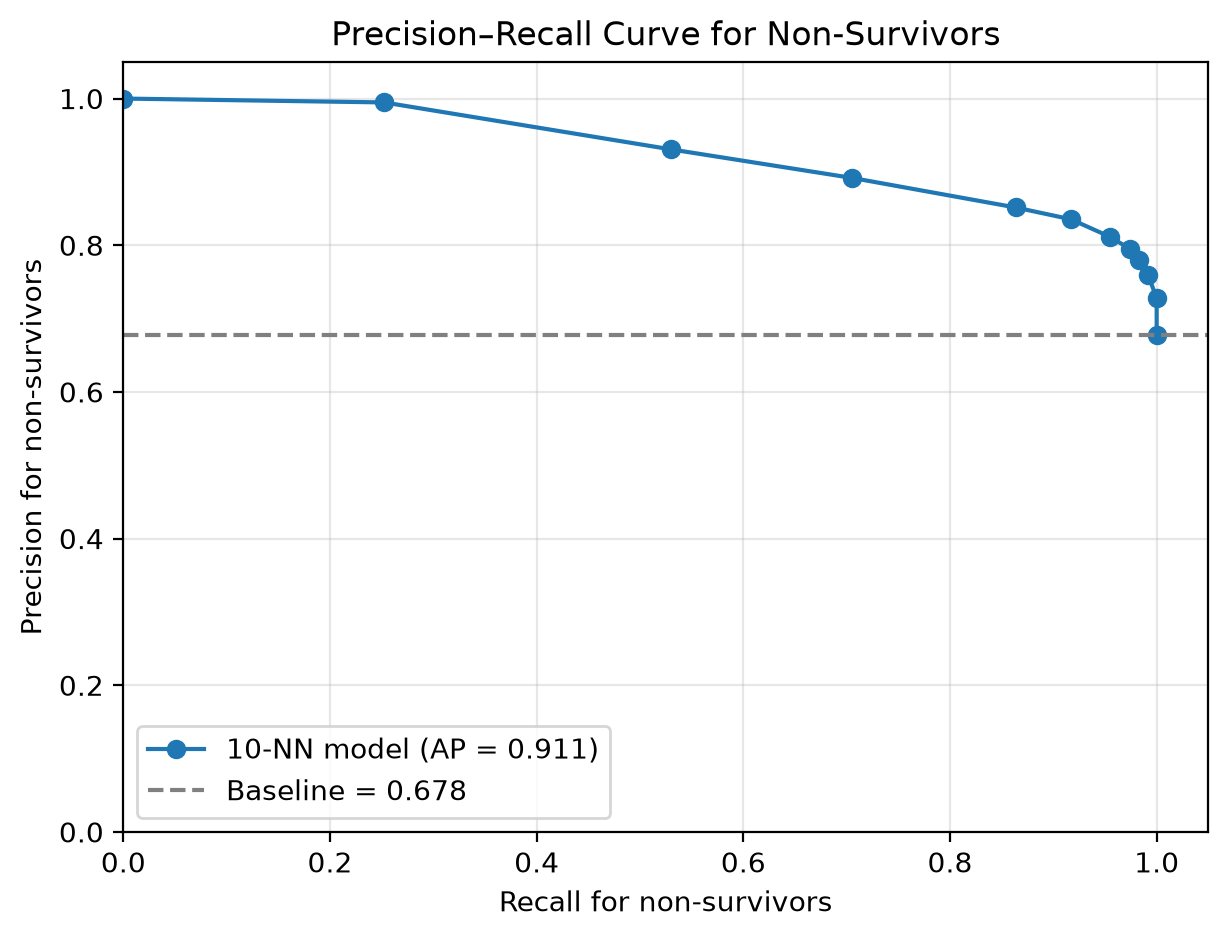

In [17]:
# YOUR CODE HERE. ADD CELLS AS NEEDED
# Create an indicator where 1 means non-survivor
actual_non_survivor = (y == 0).astype(int)

# Column 0 contains the model's predicted probability of non-survival
prob_non_survivor = titanic_model.predict_proba(X)[:, 0]

# Calculate precision and recall across all thresholds
non_survivor_precision_curve, non_survivor_recall_curve, non_survivor_thresholds = (
    precision_recall_curve(
        actual_non_survivor,
        prob_non_survivor
    )
)

# Calculate average precision
non_survivor_ap = average_precision_score(
    actual_non_survivor,
    prob_non_survivor
)

# Plot the precision-recall curve
plt.figure(figsize=(7, 5))

plt.plot(
    non_survivor_recall_curve,
    non_survivor_precision_curve,
    marker="o",
    label=f"10-NN model (AP = {non_survivor_ap:.3f})"
)

# Baseline equals the proportion of passengers who did not survive
plt.axhline(
    actual_non_survivor.mean(),
    color="gray",
    linestyle="--",
    label=f"Baseline = {actual_non_survivor.mean():.3f}"
)

plt.xlabel("Recall for non-survivors")
plt.ylabel("Precision for non-survivors")
plt.title("Precision–Recall Curve for Non-Survivors")
plt.xlim(0, 1.05)
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

The precision–recall curve shows the trade-off between precision and recall when predicting non-survivors. As the threshold for predicting non-survival increases, non-survivor precision generally increases because the model makes fewer, more confident non-survival predictions. However, recall decreases because the model fails to identify more passengers who actually did not survive. The curve is generally above the baseline of 67.76%, and its average precision is approximately 91.1%, indicating that the model performs well at identifying non-survivors. The model performs better at identifying non-survivors than survivors, although non-survivors are also the more common class in this dataset.